# How concentrated liabilities amplify systemic loss

## Comparing row concentration through majorization

For a debtor $i$, let $\pi_i^{\downarrow}$ be its relative-liability row sorted from largest to smallest. The concentrated row majorizes the dispersed row when

$$
\sum_{j=1}^{k}\pi_{i,j}^{\mathrm{concentrated},\downarrow}
\geq
\sum_{j=1}^{k}\pi_{i,j}^{\mathrm{dispersed},\downarrow},
\qquad k=1,\ldots,n-1,
$$

and both rows have the same total. Here, $k$ counts the largest creditor shares. The ring places all internal liability on one creditor, while the complete network spreads the same internal total over eleven creditors. This ordering describes the rows; it does not determine systemic loss without further conditions on assets, liabilities, and their ordering.

Row,Structure,Internal row total,Positive creditors per row,Mean squared row concentration,Largest creditor share
,String,Float64,Int64,Float64,Float64
1,Concentrated ring,0.8,1,0.64,0.8
2,Dispersed complete,0.8,11,0.0581818,0.0727273


Row,Debtor,Smallest proper cumulative gap,Total difference,Concentrated majorizes dispersed
,Int64,Float64,Float64,String
1,0,0.0,0.0,Pass
2,1,0.0,0.0,Pass
3,2,0.0,0.0,Pass
4,3,0.0,0.0,Pass
5,4,0.0,0.0,Pass
6,5,0.0,0.0,Pass
7,6,0.0,0.0,Pass
8,7,0.0,0.0,Pass
9,8,0.0,0.0,Pass


Row,Statement,Established here,Limit
,String,String,String
1,The concentrated row majorizes the dispersed row,Yes,Ordinary row ordering only
2,Concentration always raises systemic loss,No,Published conditions are required
3,Concentration always lowers systemic loss,No,Published conditions are required
4,The numerical comparison estimates a real banking system,No,Generated balance sheets only


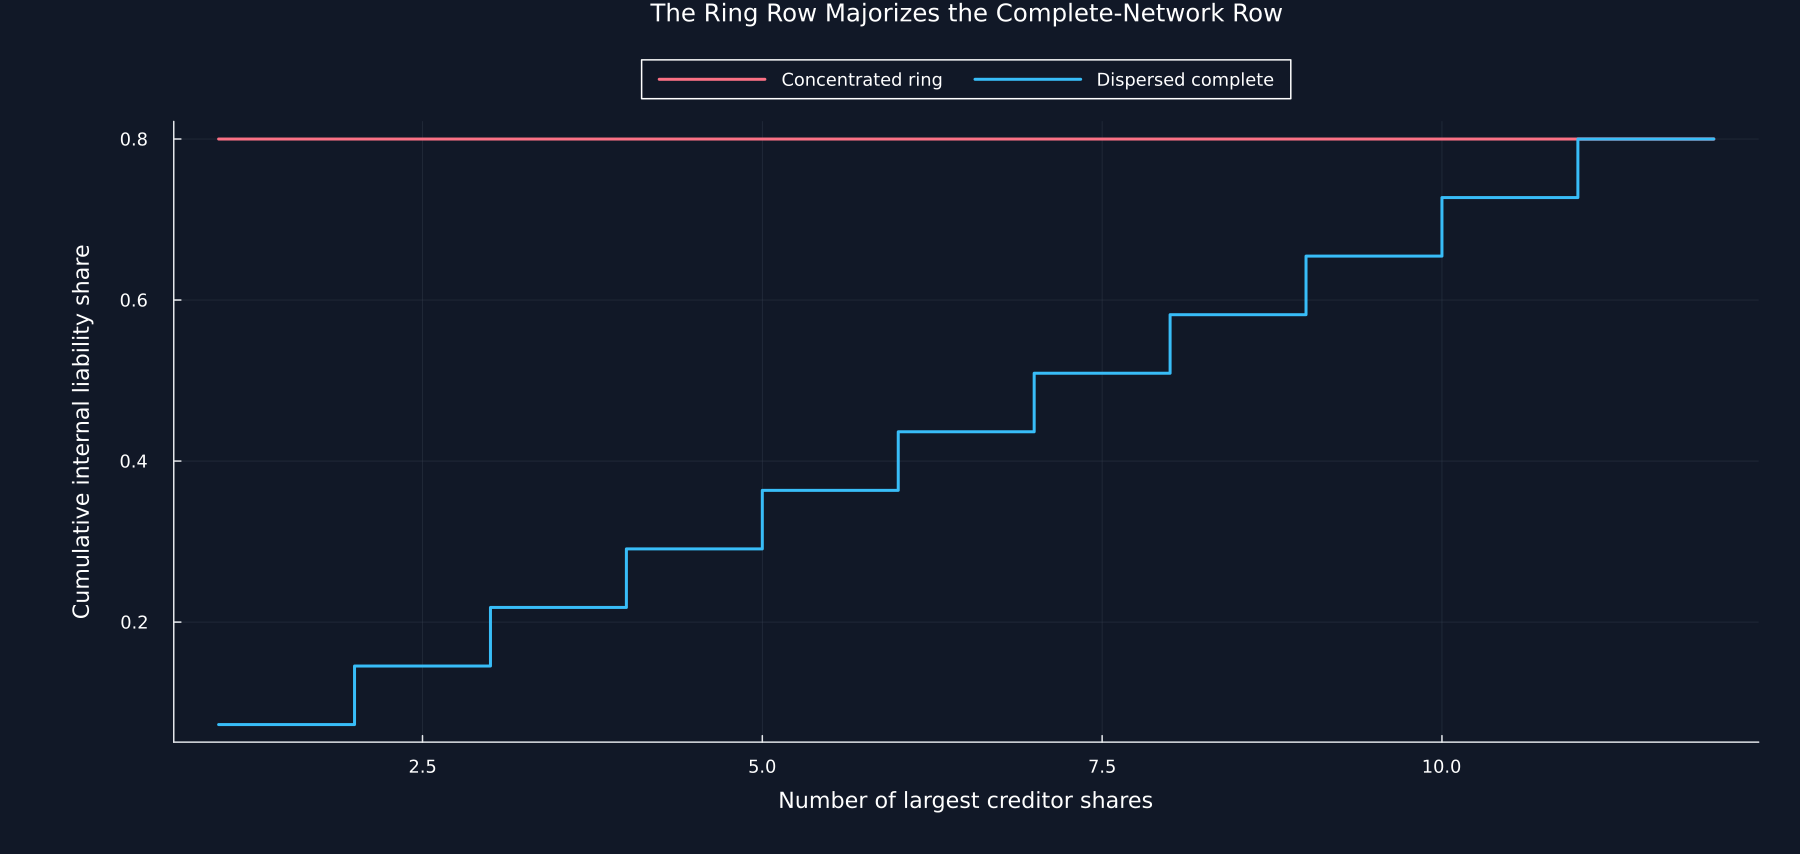

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("28_network_clearing");
using CSV, TOML, Printf, JuMP, Clarabel
include(joinpath("..","support","BookClearing.jl"))
using .BookClearing
using RiskLabAI.Optimization: eisenberg_noe_clearing
default(left_margin=12Plots.mm,bottom_margin=10Plots.mm)
violet = "#C084FC"
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter29-"*replace(name,"_"=>"-"))
    return nothing
end
random_root = joinpath("..","data","chapter28_random_inputs")
random_manifest = TOML.parsefile(joinpath(random_root,"inputs.toml"))["files"]
function primitive(name)
    path = joinpath(random_root,name)
    return Matrix{Float64}(CSV.read(path,DataFrame))
end
function network_positions(name,n)
    circle(count,radius,cx=0.0) = []
    n<=3 && return [(x,0.0) for x in range(-1,1;length=n)]
    name in ["Ring","Complete"] && return circle(n,1.0)
    name=="Core-periphery" && return vcat(circle(4,0.45),circle(n-4,1.0))
    return vcat(circle(n÷2,0.55,-0.7),circle(n-n÷2,0.55,0.7))
end
function plot_network(relative,name,stem,node_values=ones(size(relative,1)))
    n = size(relative,1)
    positions = network_positions(name,n)
    figure = plot(;title=name,aspect_ratio=:equal,axis=false,grid=false,legend=false,size=n<=3 ? (950,330) : (950,720),xlims=(-1.5,1.5),ylims=n<=3 ? (-0.35,0.35) : (-1.25,1.25))
    edge_rows = NamedTuple[]
    for debtor in 1:n,creditor in 1:n
        weight = relative[debtor,creditor]
        weight>1e-12 || continue
        push!(edge_rows,(Debtor=debtor-1,Creditor=creditor-1,relative=weight))
        start,stop = collect(positions[debtor]),collect(positions[creditor])
        direction = (stop-start)/norm(stop-start)
        start,stop = start+0.09direction,stop-0.10direction
        midpoint = (start+stop)/2+0.06norm(stop-start)*[-direction[2],direction[1]]
        curve = reduce(hcat,[(1-t)^2*start+2t*(1-t)*midpoint+t^2*stop for t in range(0,1;length=25)])
        plot!(figure,curve[1,:],curve[2,:];color="#E5E7EB",alpha=0.55,linewidth=0.8+5weight,arrow=true)
    end
    colors = [value>1e-8 ? palette.rose : palette.cyan for value in node_values]
    scatter!(figure,first.(positions),last.(positions);color=colors,markersize=13,markerstrokecolor="#E5E7EB",markerstrokewidth=0.8)
    for i in 1:n
        annotate!(figure,positions[i]...,text(string(i-1),10,"#111827",:bold))
    end
    save_figure(figure,paths,stem)
    edges = DataFrame(edge_rows)
    rename!(edges,["Debtor","Creditor","Relative liability"])
    save_data(edges,paths,stem)
    return nothing
end
function direct_linear_program(assets,nominal,relative)
    n = length(nominal)
    model = Model(Clarabel.Optimizer)
    set_silent(model)
    for name in ("tol_gap_abs","tol_gap_rel","tol_feas")
        set_optimizer_attribute(model,name,1e-14)
    end
    @variable(model,0<=payments[i=1:n]<=nominal[i])
    @constraint(model,(I-relative')*payments.<=min.(assets,nominal))
    @objective(model,Max,sum(payments))
    optimize!(model)
    @assert termination_status(model)==JuMP.MOI.OPTIMAL
    return value.(payments)
end
majorizes(source,target;tolerance=1e-12) = all(cumsum(sort(source;rev=true))[1:end-1].>=cumsum(sort(target;rev=true))[1:end-1].-tolerance)&&isapprox(sum(source),sum(target);atol=tolerance)
institution_count,internal_share = 12,0.8
concentrated,dispersed = ring_matrix(institution_count,internal_share),complete_matrix(institution_count,internal_share)
summary = DataFrame([(Structure=name,total=mean(sum(matrix;dims=2)),positive=count(>(0),matrix[1,:]),concentration=mean(sum(abs2,matrix;dims=2)),largest=maximum(matrix)) for (name,matrix) in [("Concentrated ring",concentrated),("Dispersed complete",dispersed)]])
rename!(summary,["Structure","Internal row total","Positive creditors per row","Mean squared row concentration","Largest creditor share"])
table(summary,"concentration_summary","Row totals and concentration measures for the two liability structures.")
majorization_rows = NamedTuple[]
for debtor in 1:institution_count
    source,target = sort(concentrated[debtor,:];rev=true),sort(dispersed[debtor,:];rev=true)
    gaps = cumsum(source)-cumsum(target)
    push!(majorization_rows,(Debtor=debtor-1,smallest=max(minimum(gaps[1:end-1]),0.0),total=abs(gaps[end])<=1e-12 ? 0.0 : gaps[end],majorizes=majorizes(source,target)))
end
majorization = DataFrame(majorization_rows)
rename!(majorization,["Debtor","Smallest proper cumulative gap","Total difference","Concentrated majorizes dispersed"])
@assert all(majorization[!,"Concentrated majorizes dispersed"])
table(majorization,"row_majorization_checks","Majorization checks for every generated liability row.")
conditions = DataFrame("Statement"=>["The concentrated row majorizes the dispersed row","Concentration always raises systemic loss","Concentration always lowers systemic loss","The numerical comparison estimates a real banking system"],"Established here"=>["Yes","No","No","No"],"Limit"=>["Ordinary row ordering only","Published conditions are required","Published conditions are required","Generated balance sheets only"])
table(conditions,"concentration_conditions","Claims established and not established by row majorization.")
cumulative = DataFrame("Rank"=>1:institution_count,"Concentrated cumulative share"=>cumsum(sort(concentrated[1,:];rev=true)),"Dispersed cumulative share"=>cumsum(sort(dispersed[1,:];rev=true)))
save_data(cumulative,paths,"row_cumulative_concentration")
figure = plot(cumulative.Rank,cumulative[!,"Concentrated cumulative share"];seriestype=:steppost,color=palette.rose,label="Concentrated ring",xlabel="Number of largest creditor shares",ylabel="Cumulative internal liability share",title="The Ring Row Majorizes the Complete-Network Row",legend=:outertop,legend_columns=2,size=(1200,570),left_margin=16Plots.mm)
plot!(figure,cumulative.Rank,cumulative[!,"Dispersed cumulative share"];seriestype=:steppost,color=palette.cyan,label="Dispersed complete")
save_figure(figure,paths,"row_cumulative_concentration")


## Two Hundred Generated Comparisons

For generated balance sheet $b$, define the loss difference

$$
\Delta_b
=
\sum_{i=1}^{12}\left(\overline p_{b,i}-p^{\mathrm{concentrated}}_{b,i}\right)
-
\sum_{i=1}^{12}\left(\overline p_{b,i}-p^{\mathrm{dispersed}}_{b,i}\right).
$$

The value $\Delta_b$ is positive when the concentrated ring has more unpaid liability and negative when it has less. Each run changes external assets and liability sizes but preserves the same $0.8$ internal row total. The experiment looks for both directions rather than imposing a winner.

Row,Setting,Value
,String,String
1,Generated balance sheets,200
2,First seed,290300
3,Last seed,290499
4,Institutions,12
5,Internal row total,0.8
6,Liability lognormal scale,0.75
7,External asset ratio range,0.02 to 0.75


Row,Loss direction,Generated runs,Share
,String,Int64,Float64
1,Concentrated higher,182,0.91
2,Concentrated lower,18,0.09
3,Numerically equal,0,0.0


Row,Concentrated unpaid,Case,Dispersed unpaid,Concentrated minus dispersed,Concentrated defaults,Dispersed defaults
,Float64,String,Float64,Float64,Int64,Int64
1,1.53106,Concentrated lower,2.78018,-1.24912,3,5
2,2.83515,Concentrated higher,0.729894,2.10525,6,4


Row,Case,Draw,Institution,External assets,Nominal liabilities,Concentrated unpaid,Dispersed unpaid
,String,Int64,Int64,Float64,Float64,Float64,Float64
1,Concentrated lower,100,0,0.204643,0.68518,0.0,0.0
2,Concentrated lower,100,1,0.512875,0.9655,0.0,0.0
3,Concentrated lower,100,2,0.862521,2.5525,0.917581,1.12338
4,Concentrated lower,100,3,0.350049,1.55511,0.0,0.603725
5,Concentrated lower,100,4,0.0757733,1.28007,0.0,0.584357
6,Concentrated lower,100,5,0.332071,1.21332,0.0,0.278686
7,Concentrated lower,100,6,0.373889,0.569576,0.0,0.0
8,Concentrated lower,100,7,0.27214,0.621311,0.0,0.0
9,Concentrated lower,100,8,0.226963,0.334852,0.0,0.0


Row,Statistic,Value
,String,Float64
1,Mean,0.679932
2,Standard deviation,0.572194
3,Minimum,-1.24912
4,25th percentile,0.362382
5,Median,0.671372
6,75th percentile,1.03925
7,Maximum,2.10525


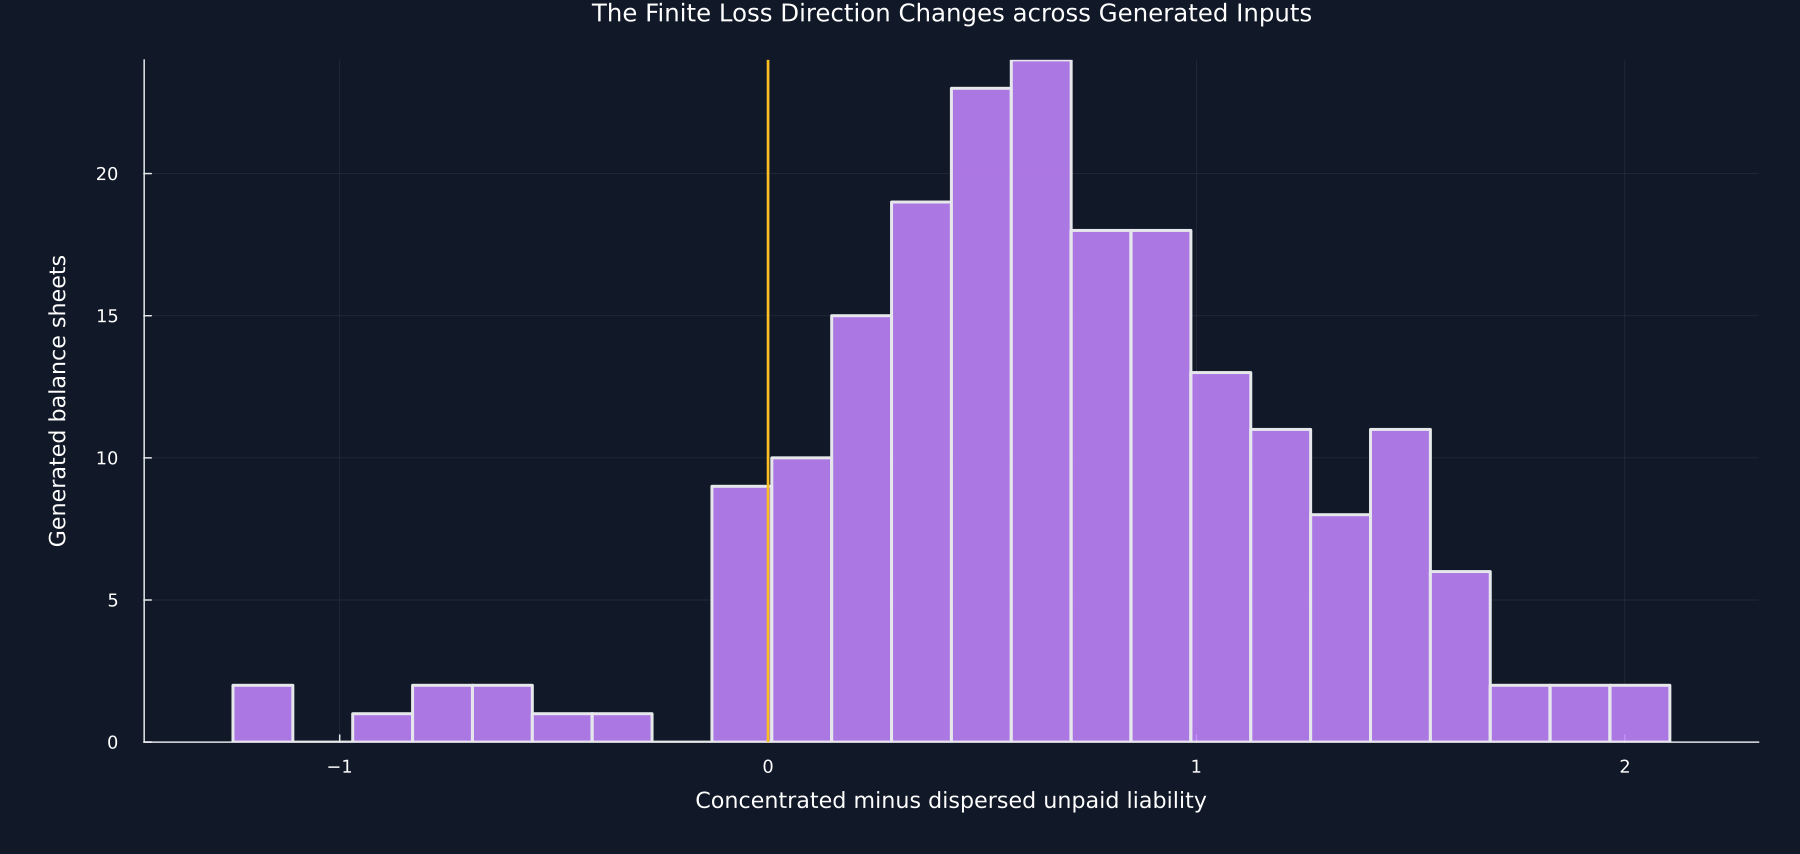

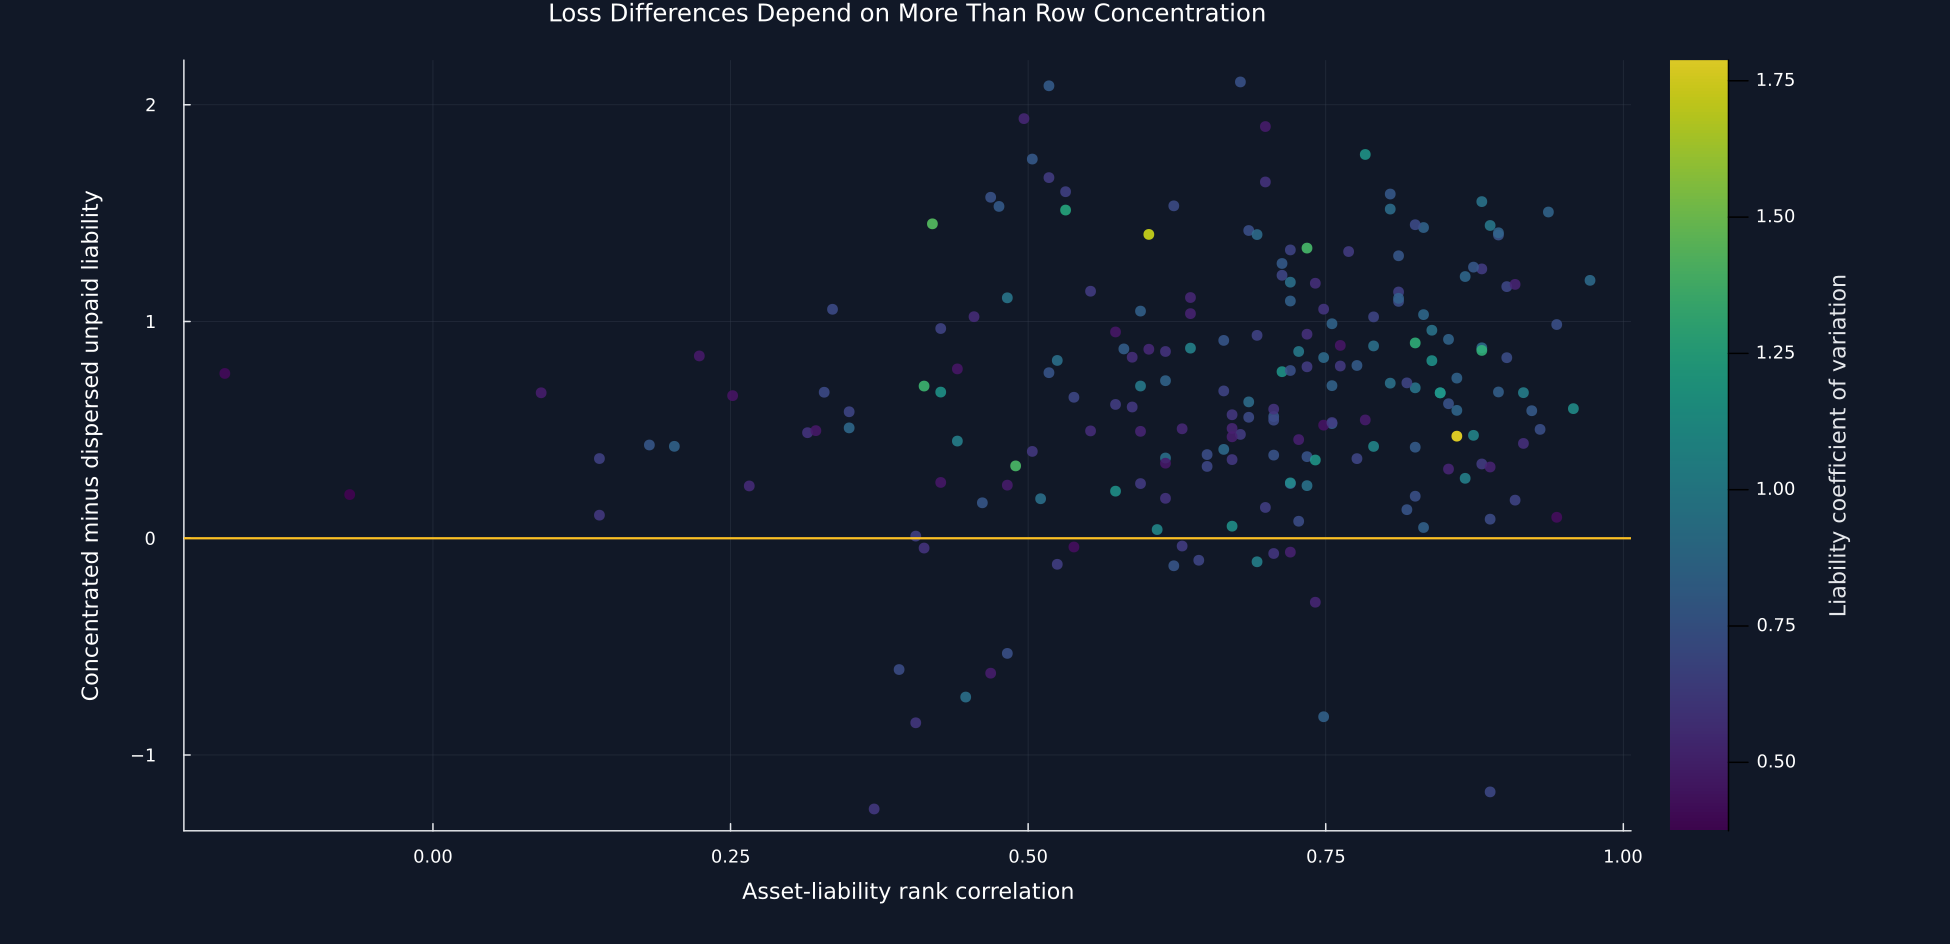

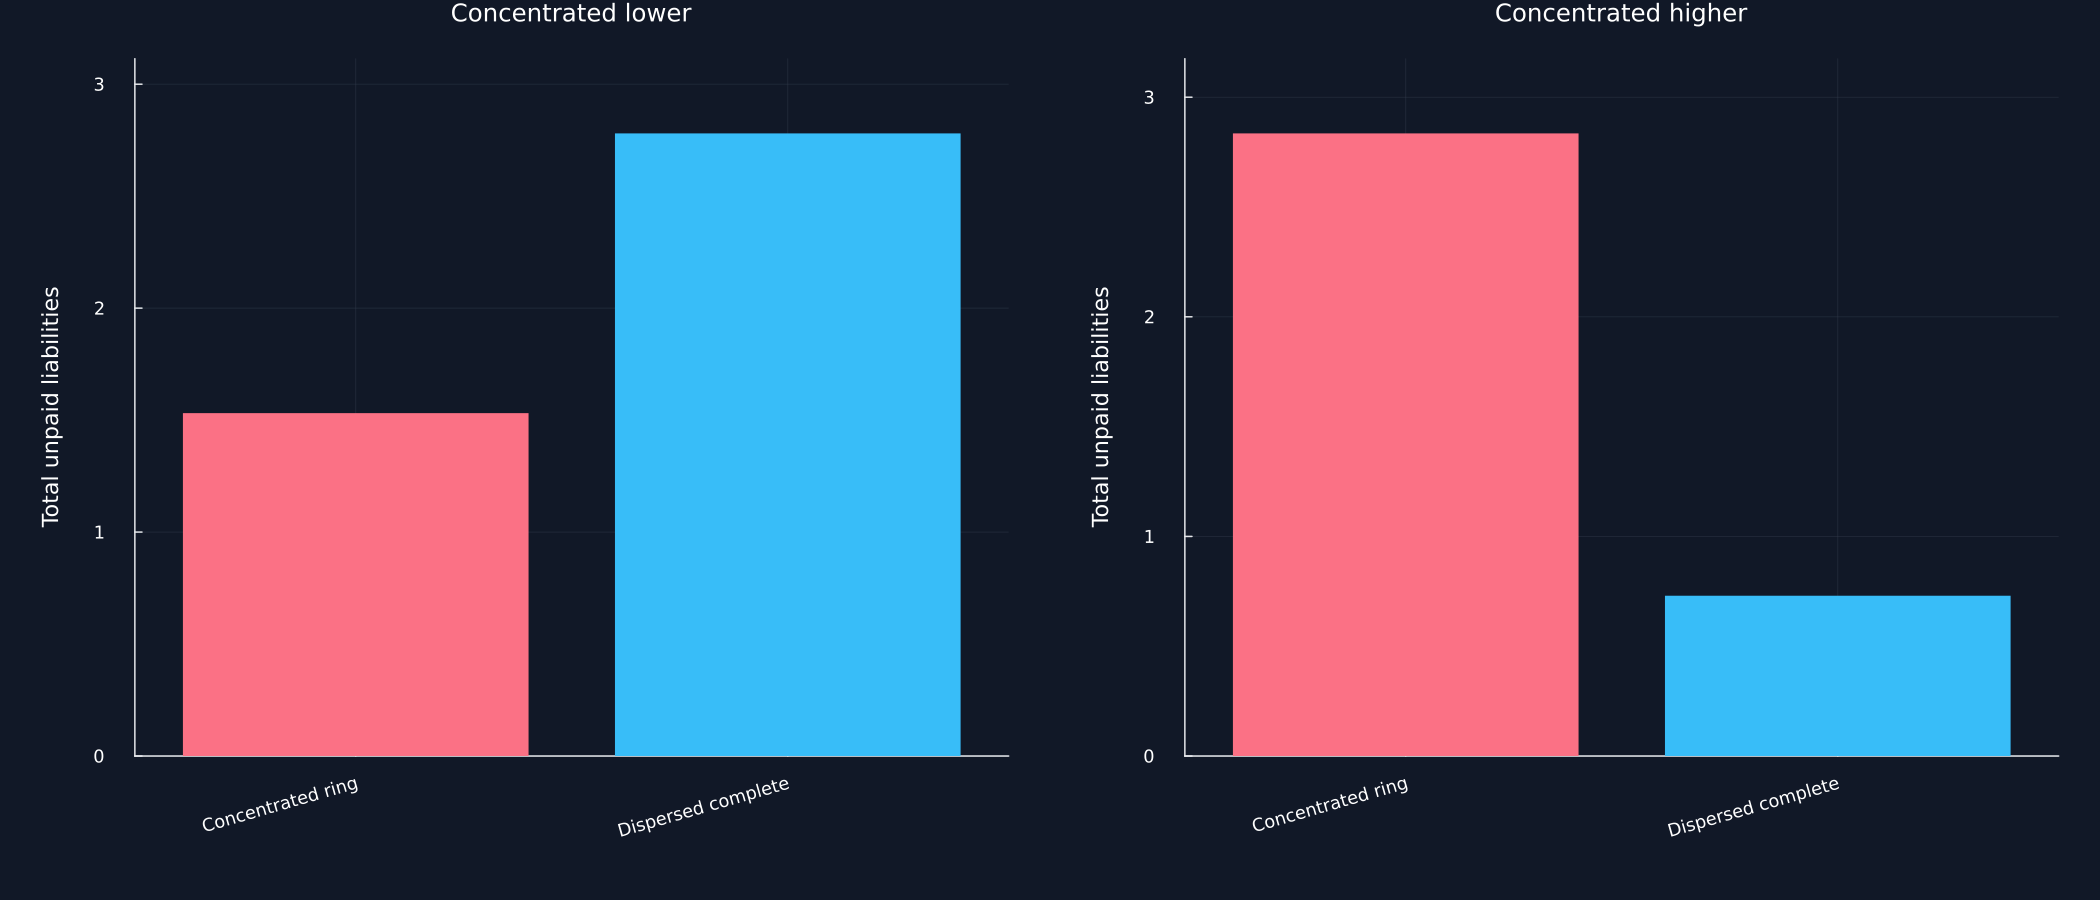

In [2]:
function average_ranks(values)
    order = sortperm(values;alg=MergeSort)
    ranks = zeros(length(values))
    left = 1
    while left<=length(values)
        right = left
        while right<length(values)&&values[order[right+1]]==values[order[left]]
            right += 1
        end
        ranks[order[left:right]] .= (left+right)/2
        left = right+1
    end
    return ranks
end
normals,uniforms = primitive("concentration_normals.csv"),primitive("concentration_uniforms.csv")
comparison_rows,saved_inputs = NamedTuple[],Dict{Int,Any}()
for draw in 1:200
    liabilities = 100exp.(0.75normals[draw,:])
    liabilities ./= mean(liabilities)
    asset_ratio = 0.02.+0.73uniforms[draw,:]
    assets = liabilities.*asset_ratio
    concentrated_result = clearing_metrics(assets,liabilities,concentrated)
    dispersed_result = clearing_metrics(assets,liabilities,dispersed)
    difference = concentrated_result.total_unpaid-dispersed_result.total_unpaid
    rank_correlation = cor(average_ranks(liabilities),average_ranks(assets))
    push!(comparison_rows,(Draw=draw-1,concentrated=concentrated_result.total_unpaid,dispersed=dispersed_result.total_unpaid,difference=difference,concentrated_defaults=concentrated_result.default_count,dispersed_defaults=dispersed_result.default_count,cv=std(liabilities)/mean(liabilities),correlation=rank_correlation,residual=max(concentrated_result.fixed_point_residual,dispersed_result.fixed_point_residual)))
    saved_inputs[draw] = (assets,liabilities,concentrated_result,dispersed_result)
end
comparisons = DataFrame(comparison_rows)
rename!(comparisons,["Draw","Concentrated unpaid","Dispersed unpaid","Concentrated minus dispersed","Concentrated defaults","Dispersed defaults","Liability coefficient of variation","Asset-liability rank correlation","Maximum fixed point residual"])
@assert any(comparisons[!,"Concentrated minus dispersed"].>1e-8)
@assert any(comparisons[!,"Concentrated minus dispersed"].< -1e-8)
seed_contract = DataFrame("Setting"=>["Generated balance sheets","First seed","Last seed","Institutions","Internal row total","Liability lognormal scale","External asset ratio range"],"Value"=>["200","290300","290499","12","0.8","0.75","0.02 to 0.75"])
table(seed_contract,"concentration_seed_contract","Fixed generation settings for liability-concentration comparisons.")
differences = comparisons[!,"Concentrated minus dispersed"]
positive,negative = count(>(1e-8),differences),count(<(-1e-8),differences)
equal = length(differences)-positive-negative
directions = DataFrame("Loss direction"=>["Concentrated higher","Concentrated lower","Numerically equal"],"Generated runs"=>[positive,negative,equal],"Share"=>[positive,negative,equal]./length(differences))
table(directions,"concentration_direction_counts","Observed loss directions across the generated comparisons.")
lower_draw,higher_draw = argmin(differences),argmax(differences)
extremes = comparisons[[lower_draw,higher_draw],["Concentrated unpaid","Dispersed unpaid","Concentrated minus dispersed","Concentrated defaults","Dispersed defaults"]]
insertcols!(extremes,2,"Case"=>["Concentrated lower","Concentrated higher"])
table(extremes,"concentration_extreme_cases","Generated cases showing opposite finite loss directions.")
node_rows = NamedTuple[]
for (draw,case) in [(lower_draw,"Concentrated lower"),(higher_draw,"Concentrated higher")]
    assets,liabilities,concentrated_result,dispersed_result = saved_inputs[draw]
    for institution in 1:institution_count
        push!(node_rows,(Case=case,Draw=draw-1,Institution=institution-1,external=assets[institution],nominal=liabilities[institution],concentrated=concentrated_result.unpaid[institution],dispersed=dispersed_result.unpaid[institution]))
    end
end
nodes = DataFrame(node_rows)
rename!(nodes,["Case","Draw","Institution","External assets","Nominal liabilities","Concentrated unpaid","Dispersed unpaid"])
table(nodes,"concentration_selected_nodes","Institution-level inputs and unpaid amounts for the two selected generated cases.")
distribution = DataFrame("Statistic"=>["Mean","Standard deviation","Minimum","25th percentile","Median","75th percentile","Maximum"],"Value"=>[mean(differences),std(differences),minimum(differences),quantile(differences,0.25),median(differences),quantile(differences,0.75),maximum(differences)])
table(distribution,"concentration_distribution_summary","Distribution of concentrated-minus-dispersed unpaid liability.")
save_data(comparisons,paths,"concentration_loss_differences")
edges = collect(range(minimum(differences),maximum(differences);length=25))
counts = zeros(Int,24)
for value in differences
    counts[clamp(searchsortedlast(edges,value),1,24)] += 1
end
@assert sum(counts)==200
centers = (edges[1:end-1]+edges[2:end])/2
figure = bar(centers,counts;bar_width=diff(edges),color=violet,fillalpha=0.88,linecolor="#E5E7EB",label="",xlabel="Concentrated minus dispersed unpaid liability",ylabel="Generated balance sheets",title="The Finite Loss Direction Changes across Generated Inputs",legend=false,size=(1200,570))
vline!(figure,[0];color=palette.amber,linewidth=1.8)
save_figure(figure,paths,"concentration_loss_differences")
scatter_data = comparisons[:,["Asset-liability rank correlation","Liability coefficient of variation","Concentrated minus dispersed"]]
save_data(scatter_data,paths,"concentration_ordering_scatter")
figure = scatter(scatter_data[!,"Asset-liability rank correlation"],scatter_data[!,"Concentrated minus dispersed"];marker_z=scatter_data[!,"Liability coefficient of variation"],color=:viridis,markersize=4,markerstrokewidth=0,alpha=0.85,colorbar=true,colorbar_title="Liability coefficient of variation",xlabel="Asset-liability rank correlation",ylabel="Concentrated minus dispersed unpaid liability",title="Loss Differences Depend on More Than Row Concentration",legend=false,size=(1300,630),left_margin=18Plots.mm,right_margin=15Plots.mm)
hline!(figure,[0];color=palette.amber,linewidth=1.5)
save_figure(figure,paths,"concentration_ordering_scatter")
bar_rows = NamedTuple[]
for (draw,case) in [(lower_draw,"Concentrated lower"),(higher_draw,"Concentrated higher")]
    push!(bar_rows,(Case=case,Structure="Concentrated ring",total=comparisons[draw,"Concentrated unpaid"]))
    push!(bar_rows,(Case=case,Structure="Dispersed complete",total=comparisons[draw,"Dispersed unpaid"]))
end
bar_data = DataFrame(bar_rows)
rename!(bar_data,"total"=>"Total unpaid")
save_data(bar_data,paths,"concentration_reversal_examples")
panels = Any[]
for case in ["Concentrated lower","Concentrated higher"]
    part = bar_data[bar_data.Case.==case,:]
    push!(panels,bar(1:2,part[!,"Total unpaid"];color=[palette.rose,palette.cyan],linealpha=0,title=case,ylabel="Total unpaid liabilities",xticks=(1:2,part.Structure),xrotation=16,legend=false,ylims=(0,1.12maximum(part[!,"Total unpaid"])),bottom_margin=15Plots.mm))
end
save_figure(plot(panels...;layout=(1,2),size=(1400,600)),paths,"concentration_reversal_examples")


## Recalculating outcomes within model scope

For every saved comparison, the fixed point residual is

$$
r_b=\max_i\left|p_{b,i}-\min\!\left(\overline p_{b,i},e_{b,i}+(\Pi^{\mathsf T}p_b)_i\right)\right|.
$$

The residual $r_b$ checks the numerical clearing identity. Recomputing selected cases with monotone iteration checks the released result by a separate route. Neither check turns a mathematical link into evidence that one institution caused another institution's observed loss.

In [3]:
recompute_rows = NamedTuple[]
for (draw,case) in [(lower_draw,"Concentrated lower"),(higher_draw,"Concentrated higher")]
    assets,liabilities,concentrated_result,dispersed_result = saved_inputs[draw]
    for (name,matrix,result) in [("Concentrated ring",concentrated,concentrated_result),("Dispersed complete",dispersed,dispersed_result)]
        iterated,history = greatest_iteration(assets,liabilities,matrix)
        push!(recompute_rows,(Case=case,Structure=name,steps=size(history,1)-1,iteration=maximum(abs.(result.payments-iterated)),fixed=result.fixed_point_residual,Pass=all(isapprox.(result.payments,iterated;atol=1e-8))))
    end
end
recomputation = DataFrame(recompute_rows)
rename!(recomputation,["Case","Structure","Iteration steps","Released versus iteration residual","Fixed point residual","Pass"])
@assert all(recomputation.Pass)
table(recomputation,"recomputation_checks","Independent recalculation checks for the two selected generated cases.")
scope = DataFrame("Question"=>["Do concentrated rows majorize dispersed rows?","Is one loss direction universal?","Are published balancing conditions tested?","Do links prove causal spillovers?","Are these actual banking-system estimates?"],"Answered"=>["Yes","No","No","No","No"],"Boundary"=>["The supplied ring and complete rows","Both directions occur in generated cases","No theorem extension","No causal design or intervention","Generated data only"])
table(scope,"causal_scope_boundaries","Interpretation boundaries for the liability-concentration experiment.")


Row,Case,Structure,Iteration steps,Released versus iteration residual,Fixed point residual,Pass
,String,String,Int64,Float64,Float64,String
1,Concentrated lower,Concentrated ring,3,2.33147e-15,1.33227e-15,Pass
2,Concentrated lower,Dispersed complete,23,2.57905e-13,1.11022e-16,Pass
3,Concentrated higher,Concentrated ring,4,1.21014e-14,1.16573e-14,Pass
4,Concentrated higher,Dispersed complete,18,2.2915e-13,3.33067e-16,Pass


Row,Question,Answered,Boundary
,String,String,String
1,Do concentrated rows majorize dispersed rows?,Yes,The supplied ring and complete rows
2,Is one loss direction universal?,No,Both directions occur in generated cases
3,Are published balancing conditions tested?,No,No theorem extension
4,Do links prove causal spillovers?,No,No causal design or intervention
5,Are these actual banking-system estimates?,No,Generated data only
